# Exercise 6.85

## a.
We choose $D(x) = x^3(1-x)$ in the heat equation. This choice for the diffusivity function suggests that the material through which heat is diffusing is not homogeneous, I think. In addition, since the diffusivity is zero at $x=0$ and $x=1$, its boundaries, this suggests that the material is perfectly insulating at the 2 ends. The maximum diffusivity occurs at some point between 2 nodes.

## b.
To solve the heat equation with a spatially varying diffusivity $D(x)$, we can implement an explicit finite difference method:

1. **Spatial Domain Discretization**:<br>
   The spatial domain $[0, 1]$ is discretized into $N$ segments.

2. **Initial Condition**:<br>
   The initial temperature distribution is given by $u(x, 0) = \sin(2\pi x)$.

3. **Boundary Conditions**:<br>
   Dirichlet boundary conditions: $u(0, t) = u(1, t) = 0$.

4. **Update in Function**:
   Time is discretized into steps $\Delta t$, and the update rule for the temperature at a point $x_i$ at the next time step $t_{n+1}$ is given by:

   $$u_i^{n+1} = u_i^n + \Delta t \left[ D(x_i)\frac{u_{i+1}^n - 2u_i^n + u_{i-1}^n}{\Delta x^2} + D'(x_i)\frac{u_{i+1}^n - u_{i-1}^n}{2\Delta x} \right]$$

   where $u_i^n$ represents the temperature at position $x_i$ and time $t_n$, and $D'(x_i)$ is the spatial derivative of $D$ at $x_i$.

**Discretization Errors**:
   Spatial discretization results in an error of order $O(\Delta x^2)$, and time discretization introduces an error of order $O(\Delta t)$.

## c.

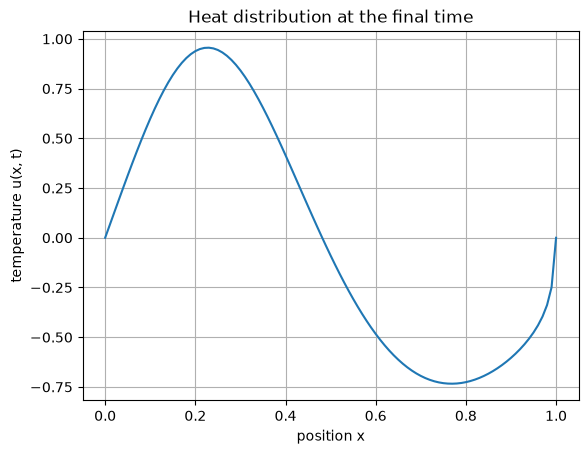

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def solve_heat_equation(Nx, Nt, dt):
    """Explicit scheme for u_t = (D(x) u_x)_x on [0, 1]."""
    D = lambda x: x**3 * (1 - x)
    D_prime = lambda x: 3 * x**2 - 4 * x**3

    dx = 1 / Nx
    x = np.linspace(0, 1, Nx + 1)
    u = np.zeros((Nt + 1, Nx + 1))
    u[0, :] = np.sin(2 * np.pi * x)
    u[:, 0] = 0
    u[:, -1] = 0

    # Vectorized interior update: all interior nodes at once.
    for n in range(Nt):
        u_xx = (u[n, 2:] - 2 * u[n, 1:-1] + u[n, :-2]) / dx**2
        u_x = (u[n, 2:] - u[n, :-2]) / (2 * dx)
        u[n + 1, 1:-1] = u[n, 1:-1] + dt * (D(x[1:-1]) * u_xx + D_prime(x[1:-1]) * u_x)
    return u, x


Nx = 100
Nt = 1000
dt = 0.0001
u, x = solve_heat_equation(Nx, Nt, dt)

plt.plot(x, u[-1])
plt.title("Heat distribution at the final time")
plt.xlabel("position x")
plt.ylabel("temperature u(x, t)")
plt.grid(True)
plt.show()


## d.

To ensure the stability using the explicit finite difference method, we need to carefully choose $\Delta x$ and $\Delta t$. Based on the error analysis, spatial discretization results in an error of order $O(\Delta x^2)$, and time discretization introduces an error of order $O(\Delta t)$. The error decreases with smaller spatial discretization, leading to a more accurate approximation of spatial derivatives. Similarly, a smaller $\Delta t$ reduces the time discretization error, improving the accuracy of the simulation over time. However, we need to be careful with the trade-off game here, smaller time steps will increase computational costs as the number of iterations  increases. Thus, I tried some relatively balanced numbers for an appropriate plot.

## e. 

In [2]:
from scipy.integrate import quad

D_func = lambda x: x**3 * (1 - x)
D_ave = quad(D_func, 0, 1)[0]
print(f"average diffusivity: {D_ave:.6f}")


average diffusivity: 0.050000


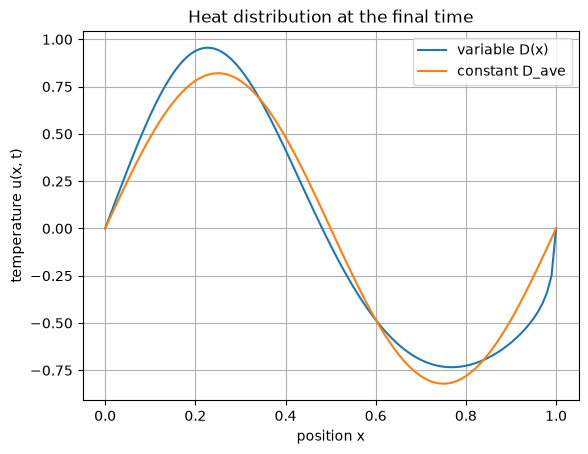

In [3]:
def solve_heat_equation_constant_diffusivity(Nx, Nt, dt, D_ave):
    """Explicit scheme with a constant, averaged diffusivity."""
    dx = 1 / Nx
    x = np.linspace(0, 1, Nx + 1)
    u = np.zeros((Nt + 1, Nx + 1))
    u[0, :] = np.sin(2 * np.pi * x)
    u[:, 0] = u[:, -1] = 0

    for n in range(Nt):
        u_xx = (u[n, 2:] - 2 * u[n, 1:-1] + u[n, :-2]) / dx**2
        u[n + 1, 1:-1] = u[n, 1:-1] + dt * D_ave * u_xx
    return u, x


u_const, x = solve_heat_equation_constant_diffusivity(Nx, Nt, dt, D_ave)

plt.plot(x, u[-1], label="variable D(x)")
plt.plot(x, u_const[-1], label="constant D_ave")
plt.title("Heat distribution at the final time")
plt.xlabel("position x")
plt.ylabel("temperature u(x, t)")
plt.legend()
plt.grid(True)
plt.show()


# Exercise 6.88

Devise a numerical experiment to empirically test the error scaling:

1. Compute the analytical and numerical solutions of the heat equation for various spatial discretizations.
2. Calculate the maximum absolute error between the numerical and analytical solutions.
3. Plot the error v.s. $\Delta x^2$ on a log-log plot.

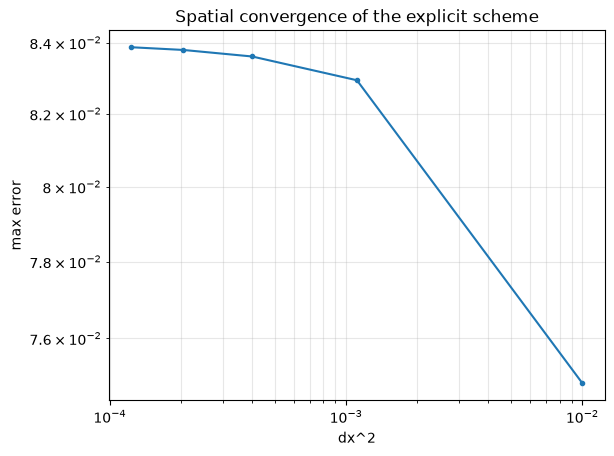

In [4]:
from scipy.integrate import quad


def D(x):
    return x**3 * (1 - x)


def analytical_solution(x, t):
    return np.exp(-t) * np.sin(2 * np.pi * x)


def numerical_solution(Nx, Nt, dt, D_ave):
    dx = 1 / Nx
    x = np.linspace(0, 1, Nx + 1)
    u = np.zeros((Nt + 1, Nx + 1))
    u[0, :] = np.sin(2 * np.pi * x)
    u[:, 0] = u[:, -1] = 0
    for n in range(Nt):
        u_xx = (u[n, 2:] - 2 * u[n, 1:-1] + u[n, :-2]) / dx**2
        u[n + 1, 1:-1] = u[n, 1:-1] + dt * D_ave * u_xx
    return u, x


dt = 0.0001
Nt = 1000
D_ave = quad(D, 0, 1)[0]
errors, dx_values = [], []

for Nx in np.arange(10, 100, 20):
    u_num, x = numerical_solution(Nx, Nt, dt, D_ave)
    error = np.max(np.abs(u_num[-1] - analytical_solution(x, Nt * dt)))
    errors.append(error)
    dx_values.append(1 / Nx)

plt.loglog(np.array(dx_values) ** 2, errors, ".-")
plt.xlabel("dx^2")
plt.ylabel("max error")
plt.title("Spatial convergence of the explicit scheme")
plt.grid(True, which="both", alpha=0.3)
plt.show()


The downward trend suggests that as the spatial step size ($\Delta x$) gets smaller, the error decreases, which expresses an improvement in the accuracy. 

# Exercise 6.91

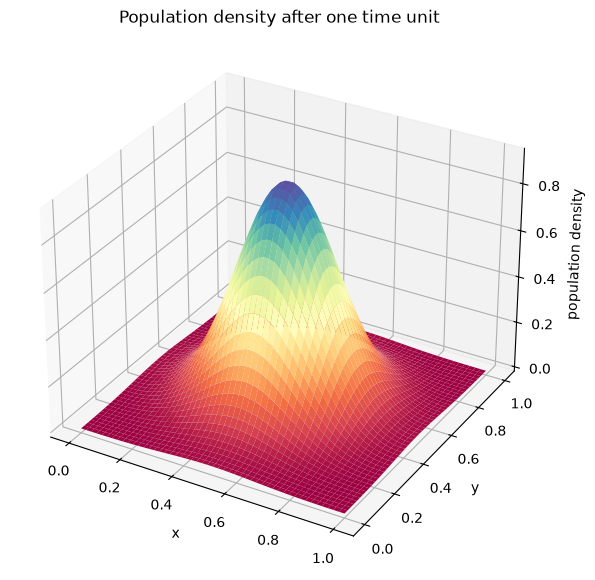

In [5]:
def logistic_growth_diffusion(k1, k2, D, N=50, t_final=1, dt=0.001):
    """Explicit 2D reaction-diffusion step, vectorized over the interior."""
    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)
    X, Y = np.meshgrid(x, y)
    dx = dy = 1 / (N - 1)

    u = np.exp(-((X - 0.5) ** 2 + (Y - 0.5) ** 2) / 0.05)

    for _ in range(int(t_final / dt)):
        u_old = u.copy()
        u_xx = (u_old[2:, 1:-1] - 2 * u_old[1:-1, 1:-1] + u_old[:-2, 1:-1]) / dx**2
        u_yy = (u_old[1:-1, 2:] - 2 * u_old[1:-1, 1:-1] + u_old[1:-1, :-2]) / dy**2
        growth = k1 * u_old[1:-1, 1:-1] * (1 - u_old[1:-1, 1:-1] / k2)
        u[1:-1, 1:-1] = u_old[1:-1, 1:-1] + dt * (growth + D * (u_xx + u_yy))

        # Neumann boundaries.
        u[0, :] = u[1, :]
        u[-1, :] = u[-2, :]
        u[:, 0] = u[:, 1]
        u[:, -1] = u[:, -2]

    return X, Y, u


k1, k2, D = 0.1, 1.0, 0.001
X, Y, u = logistic_growth_diffusion(k1, k2, D)

ax = plt.figure(figsize=(12, 7)).add_subplot(projection="3d")
ax.plot_surface(X, Y, u, cmap="Spectral")
ax.set_title("Population density after one time unit")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("population density")
plt.show()
